# Rapport d'Exploration, Data Visualisation et Pre-processing
## Challenge Rakuten France — Classification Multimodale de Produits

**Objectif :** Prédire le `prdtypecode` (catégorie produit) à partir de données textuelles (désignation, description) et images.  
**Métrique :** Weighted F1-score  
**Données :** ~84 916 produits d'entraînement, 27 classes (prdtypecodes)

---
## 1. Imports et Configuration

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import os
import re
import warnings
from collections import Counter
from html.parser import HTMLParser
import unicodedata

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

# Chemins
BASE_PATH = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data"
RAW_PATH = os.path.join(BASE_PATH, "raw")
PROCESSED_PATH = os.path.join(BASE_PATH, "processed_final")
X_TRAIN_PATH = os.path.join(RAW_PATH, "X_train_update.csv")
Y_TRAIN_PATH = os.path.join(RAW_PATH, "Y_train.csv")
X_TEST_PATH  = os.path.join(RAW_PATH, "X_test_update.csv")
IMG_TRAIN_PATH = os.path.join(RAW_PATH, r"images\image_train")
IMG_TEST_PATH  = os.path.join(RAW_PATH, r"images\image_test")

print("Imports OK")

Imports OK


---
## 2. Chargement des Données

In [30]:
X_train = pd.read_csv(X_TRAIN_PATH, index_col=0)
Y_train = pd.read_csv(Y_TRAIN_PATH, index_col=0)
X_test  = pd.read_csv(X_TEST_PATH,  index_col=0)

# Fusion train
train = X_train.join(Y_train)

print(f"X_train : {X_train.shape}")
print(f"Y_train : {Y_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"Train fusionné : {train.shape}")
print(f"\nColonnes : {train.columns.tolist()}")

X_train : (84916, 4)
Y_train : (84916, 1)
X_test  : (13812, 4)
Train fusionné : (84916, 5)

Colonnes : ['designation', 'description', 'productid', 'imageid', 'prdtypecode']


In [31]:
train.head(3)

,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,50


In [32]:
train.dtypes

designation      str
description      str
productid      int64
imageid        int64
prdtypecode    int64
dtype: object

---
## 3. Exploration des Données
### 3.1 Valeurs manquantes

Valeurs manquantes :


,count,%
designation,0,0.000000
description,29800,35.093504
productid,0,0.000000
imageid,0,0.000000
prdtypecode,0,0.000000


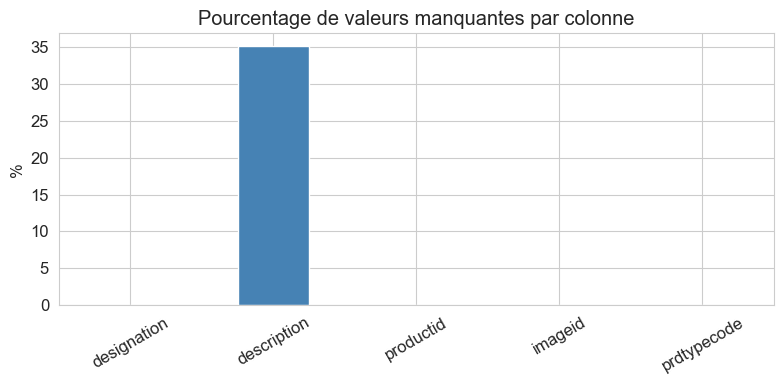

In [33]:
missing = train.isnull().sum().rename('count')
missing_pct = (train.isnull().mean() * 100).rename('%')
df_missing = pd.concat([missing, missing_pct], axis=1)
print("Valeurs manquantes :")
display(df_missing)

# Visualisation
fig, ax = plt.subplots(figsize=(8, 4))
df_missing['%'].plot(kind='bar', ax=ax, color='steelblue')
ax.set_title("Pourcentage de valeurs manquantes par colonne")
ax.set_ylabel("%")
ax.set_xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 3.2 Doublons

In [34]:
print(f"Doublons sur toutes les colonnes : {train.duplicated().sum()}")
print(f"Doublons sur 'designation'       : {train['designation'].duplicated().sum()}")
print(f"Doublons sur 'productid'         : {train['productid'].duplicated().sum()}")

Doublons sur toutes les colonnes : 0
Doublons sur 'designation'       : 2651
Doublons sur 'productid'         : 0


### 3.3 Distribution de la variable cible (prdtypecode)

In [35]:
n_classes = train['prdtypecode'].nunique()
print(f"Nombre de classes : {n_classes}")
print(f"\nDistribution des classes (top 10) :")
display(train['prdtypecode'].value_counts().head(10).to_frame())

Nombre de classes : 27

Distribution des classes (top 10) :


,count
prdtypecode,
2583,10209
1560,5073
1300,5045
2060,4993
2522,4989
1280,4870
2403,4774
2280,4760
1920,4303


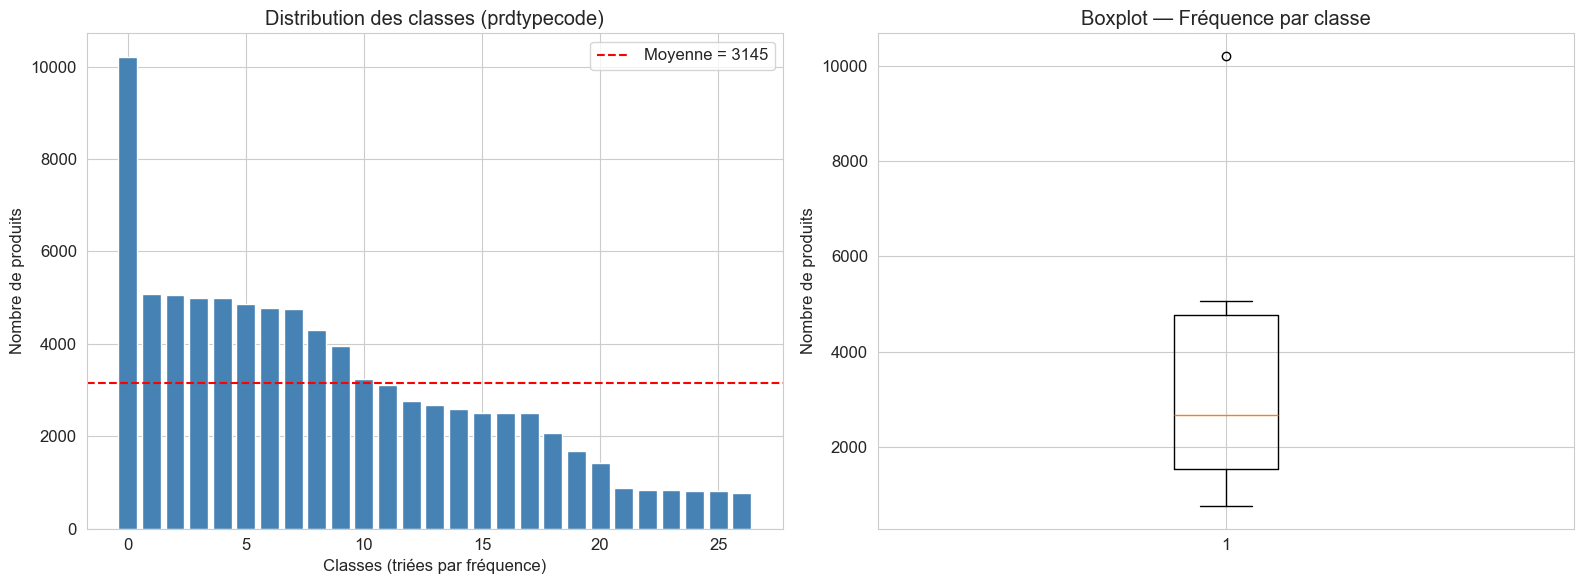


Classe la plus fréquente : 2583 (10209 produits)
Classe la moins fréquente : 1180 (764 produits)
Ratio max/min : 13.4x


In [36]:
class_counts = train['prdtypecode'].value_counts().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barplot
axes[0].bar(range(len(class_counts)), class_counts.values, color='steelblue')
axes[0].set_title("Distribution des classes (prdtypecode)")
axes[0].set_xlabel("Classes (triées par fréquence)")
axes[0].set_ylabel("Nombre de produits")
axes[0].axhline(y=class_counts.mean(), color='red', linestyle='--', label=f'Moyenne = {class_counts.mean():.0f}')
axes[0].legend()

# Boxplot pour visualiser le déséquilibre
axes[1].boxplot(class_counts.values, vert=True)
axes[1].set_title("Boxplot — Fréquence par classe")
axes[1].set_ylabel("Nombre de produits")

plt.tight_layout()
plt.show()

print(f"\nClasse la plus fréquente : {class_counts.index[0]} ({class_counts.iloc[0]} produits)")
print(f"Classe la moins fréquente : {class_counts.index[-1]} ({class_counts.iloc[-1]} produits)")
print(f"Ratio max/min : {class_counts.iloc[0]/class_counts.iloc[-1]:.1f}x")

---
## 4. Analyse des Données Textuelles
### 4.1 Longueur des textes

In [37]:
train['desig_len_chars'] = train['designation'].fillna('').apply(len)
train['desig_len_words'] = train['designation'].fillna('').apply(lambda x: len(x.split()))
train['desc_len_chars']  = train['description'].fillna('').apply(len)
train['desc_len_words']  = train['description'].fillna('').apply(lambda x: len(x.split()) if isinstance(x, str) else 0)
train['has_description'] = train['description'].notna().astype(int)

print("Statistiques — Désignation (en mots) :")
display(train['desig_len_words'].describe().to_frame().T)

print("\nStatistiques — Description (en mots, produits ayant une description) :")
display(train.loc[train['has_description']==1, 'desc_len_words'].describe().to_frame().T)

Statistiques — Désignation (en mots) :


,count,mean,std,min,25%,50%,75%,max
desig_len_words,84916.0,11.557374,6.207966,3.0,7.0,11.0,14.0,56.0



Statistiques — Description (en mots, produits ayant une description) :


,count,mean,std,min,25%,50%,75%,max
desc_len_words,55116.0,123.510959,123.158437,1.0,39.0,95.0,161.0,2068.0


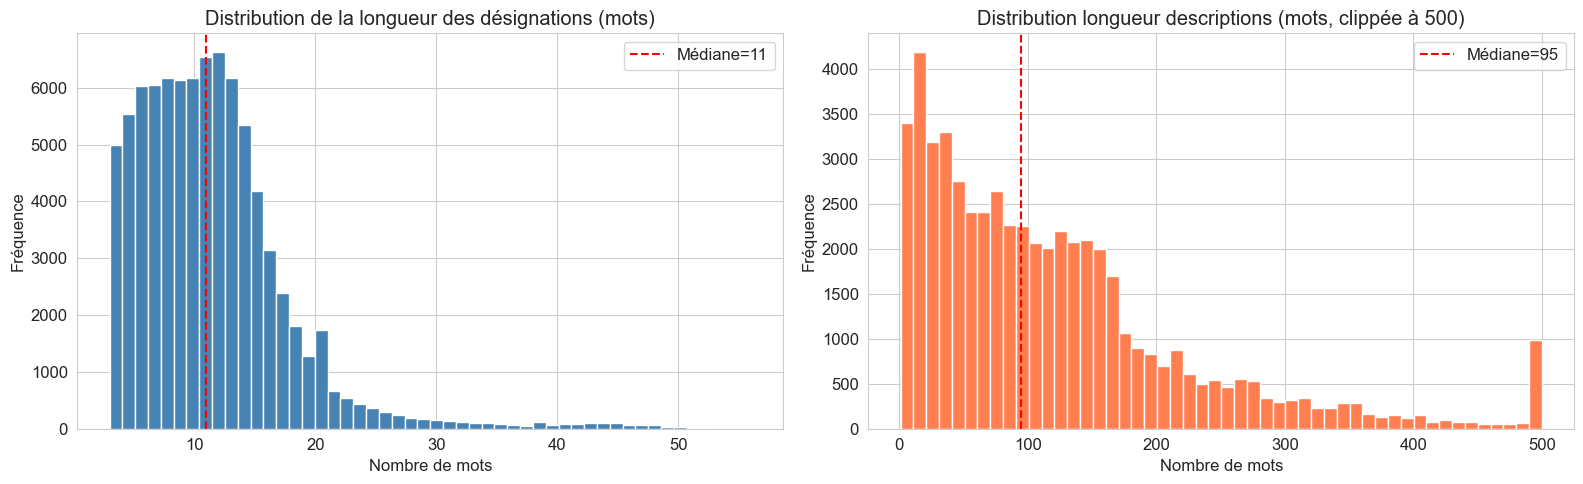

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(train['desig_len_words'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title("Distribution de la longueur des désignations (mots)")
axes[0].set_xlabel("Nombre de mots")
axes[0].set_ylabel("Fréquence")
axes[0].axvline(train['desig_len_words'].median(), color='red', linestyle='--', label=f"Médiane={train['desig_len_words'].median():.0f}")
axes[0].legend()

desc_words = train.loc[train['has_description']==1, 'desc_len_words'].clip(upper=500)
axes[1].hist(desc_words, bins=50, color='coral', edgecolor='white')
axes[1].set_title("Distribution longueur descriptions (mots, clippée à 500)")
axes[1].set_xlabel("Nombre de mots")
axes[1].set_ylabel("Fréquence")
axes[1].axvline(desc_words.median(), color='red', linestyle='--', label=f"Médiane={desc_words.median():.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.2 Présence de description par classe

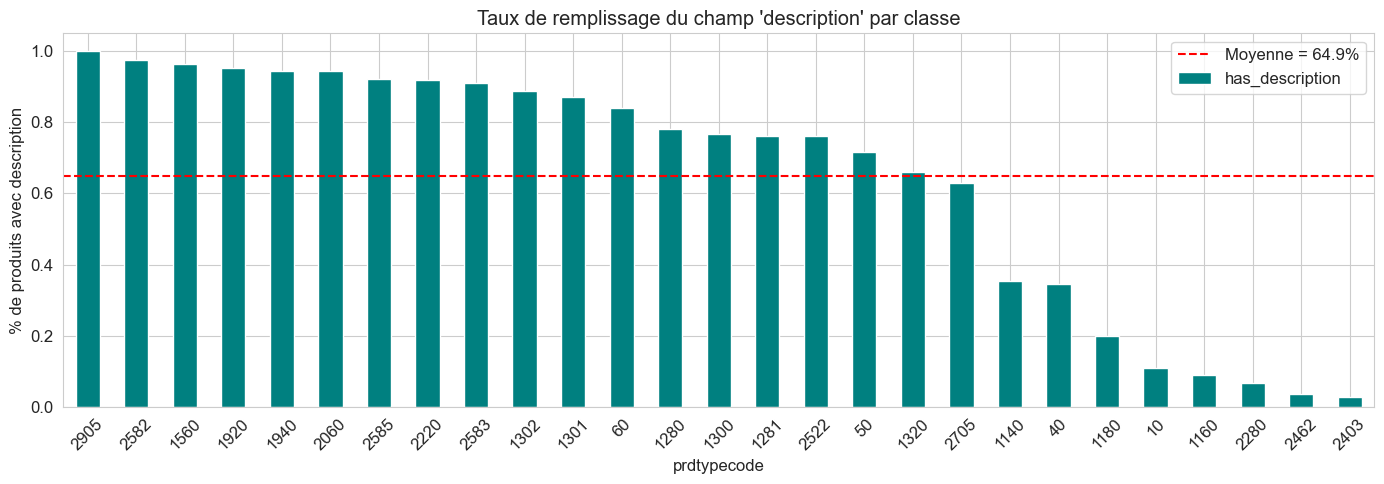

In [39]:
desc_by_class = train.groupby('prdtypecode')['has_description'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
desc_by_class.plot(kind='bar', ax=ax, color='teal')
ax.set_title("Taux de remplissage du champ 'description' par classe")
ax.set_xlabel("prdtypecode")
ax.set_ylabel("% de produits avec description")
ax.axhline(y=train['has_description'].mean(), color='red', linestyle='--', label=f"Moyenne = {train['has_description'].mean():.1%}")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.3 Longueur des désignations par classe

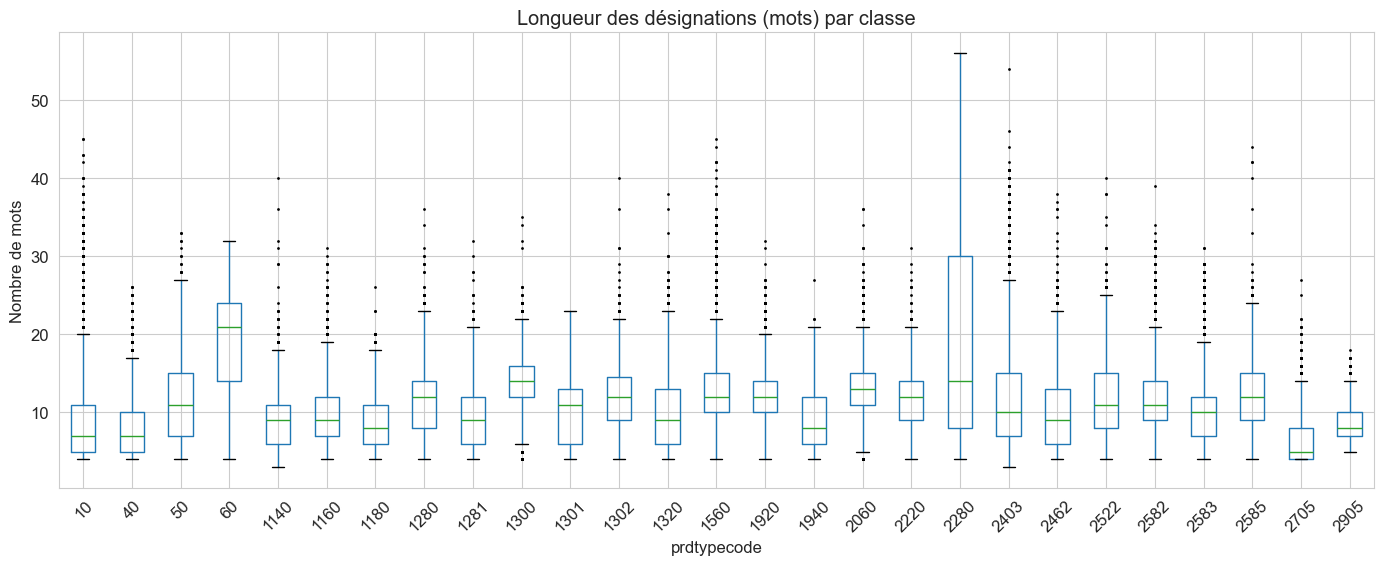

In [40]:
fig, ax = plt.subplots(figsize=(14, 6))
train.boxplot(column='desig_len_words', by='prdtypecode', ax=ax, 
              flierprops=dict(marker='.', markersize=2))
ax.set_title("Longueur des désignations (mots) par classe")
ax.set_xlabel("prdtypecode")
ax.set_ylabel("Nombre de mots")
plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.4 Détection de la langue (échantillon)

Distribution des langues (échantillon 5000) :


,count
designation,
fr,2931
other,1843
en,226


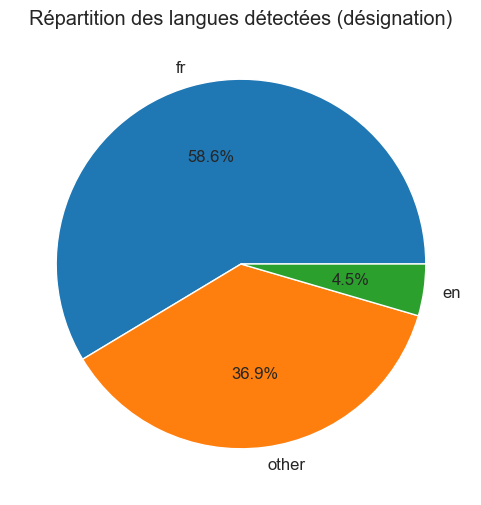

In [41]:
# Heuristique simple : mots courants français vs anglais
FR_WORDS = {'le','la','les','de','du','des','un','une','et','en','pour','avec','sur','dans','par','est','qui','que','au','aux','ce','se','il','elle'}
EN_WORDS = {'the','a','an','of','to','in','and','for','with','on','is','are','was','were','this','that','it','by','at','from'}

def detect_lang(text):
    if not isinstance(text, str):
        return 'unknown'
    words = set(text.lower().split())
    fr = len(words & FR_WORDS)
    en = len(words & EN_WORDS)
    if fr == 0 and en == 0:
        return 'other'
    return 'fr' if fr >= en else 'en'

sample = train.sample(5000, random_state=42)
sample_lang = sample['designation'].apply(detect_lang)

lang_counts = sample_lang.value_counts()
print("Distribution des langues (échantillon 5000) :")
display(lang_counts.to_frame())

lang_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))
plt.title("Répartition des langues détectées (désignation)")
plt.ylabel('')
plt.show()

---
### 4.5 Analyse approfondie des langues (langdetect)

> **Question clé :** faut-il traduire les textes en français avant de modéliser ?

In [42]:
from langdetect import detect, LangDetectException
from langdetect import DetectorFactory
DetectorFactory.seed = 42  # reproductibilité

def safe_detect(text):
    """Détecte la langue, retourne 'unknown' si échec."""
    if not isinstance(text, str) or len(text.strip()) < 10:
        return 'unknown'
    try:
        return detect(text)
    except LangDetectException:
        return 'unknown'

# Échantillon 3000 pour la vitesse (langdetect est lent)
SAMPLE_N = 3000
sample_ld = train.sample(SAMPLE_N, random_state=42).copy()

print(f"Détection de langue sur {SAMPLE_N} produits...")
sample_ld['lang_designation']  = sample_ld['designation'].apply(safe_detect)
sample_ld['lang_description']  = sample_ld['description'].apply(safe_detect)

print("Terminé.")
print(f"\n--- Désignation ---")
print(sample_ld['lang_designation'].value_counts().head(10).to_string())
print(f"\n--- Description ---")
print(sample_ld['lang_description'].value_counts().head(10).to_string())

Détection de langue sur 3000 produits...
Terminé.

--- Désignation ---
lang_designation
fr    1866
en     648
de     191
nl      74
ca      58
it      33
ro      24
pt      22
es      14
no      14

--- Description ---
lang_description
fr         1772
unknown    1029
en          154
de           18
ca            5
it            3
pt            3
sv            3
vi            2
pl            2


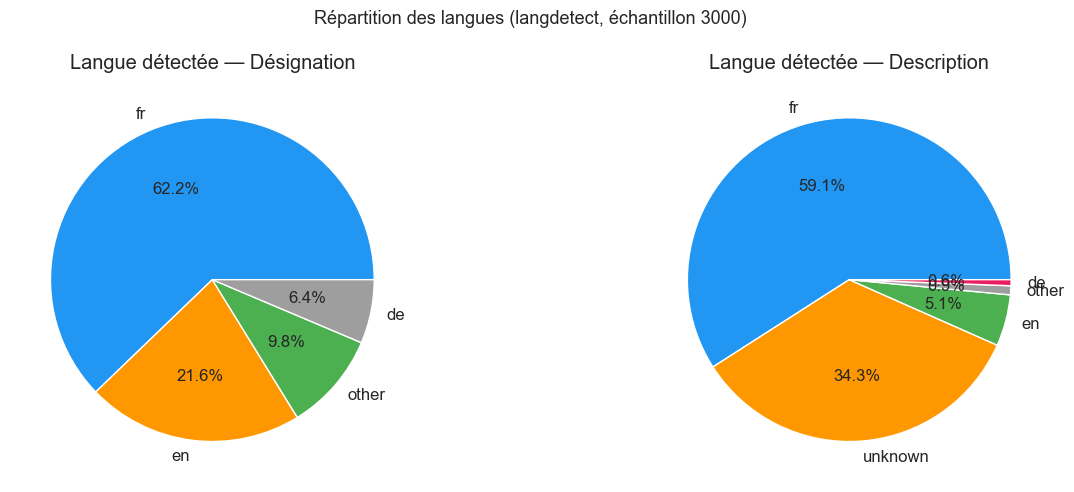

In [43]:
# Regrouper les langues rares en "other"
TOP_LANGS = ['fr', 'en', 'de', 'unknown']

def group_lang(lang):
    return lang if lang in TOP_LANGS else 'other'

sample_ld['lang_desig_grp'] = sample_ld['lang_designation'].apply(group_lang)
sample_ld['lang_desc_grp']  = sample_ld['lang_description'].apply(group_lang)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Désignation
lang_d = sample_ld['lang_desig_grp'].value_counts()
colors_d = ['#2196F3','#FF9800','#4CAF50','#9E9E9E','#E91E63']
axes[0].pie(lang_d.values, labels=lang_d.index, autopct='%1.1f%%', colors=colors_d[:len(lang_d)])
axes[0].set_title("Langue détectée — Désignation")

# Description
lang_desc = sample_ld['lang_desc_grp'].value_counts()
axes[1].pie(lang_desc.values, labels=lang_desc.index, autopct='%1.1f%%', colors=colors_d[:len(lang_desc)])
axes[1].set_title("Langue détectée — Description")

plt.suptitle("Répartition des langues (langdetect, échantillon 3000)", fontsize=13)
plt.tight_layout()
plt.show()

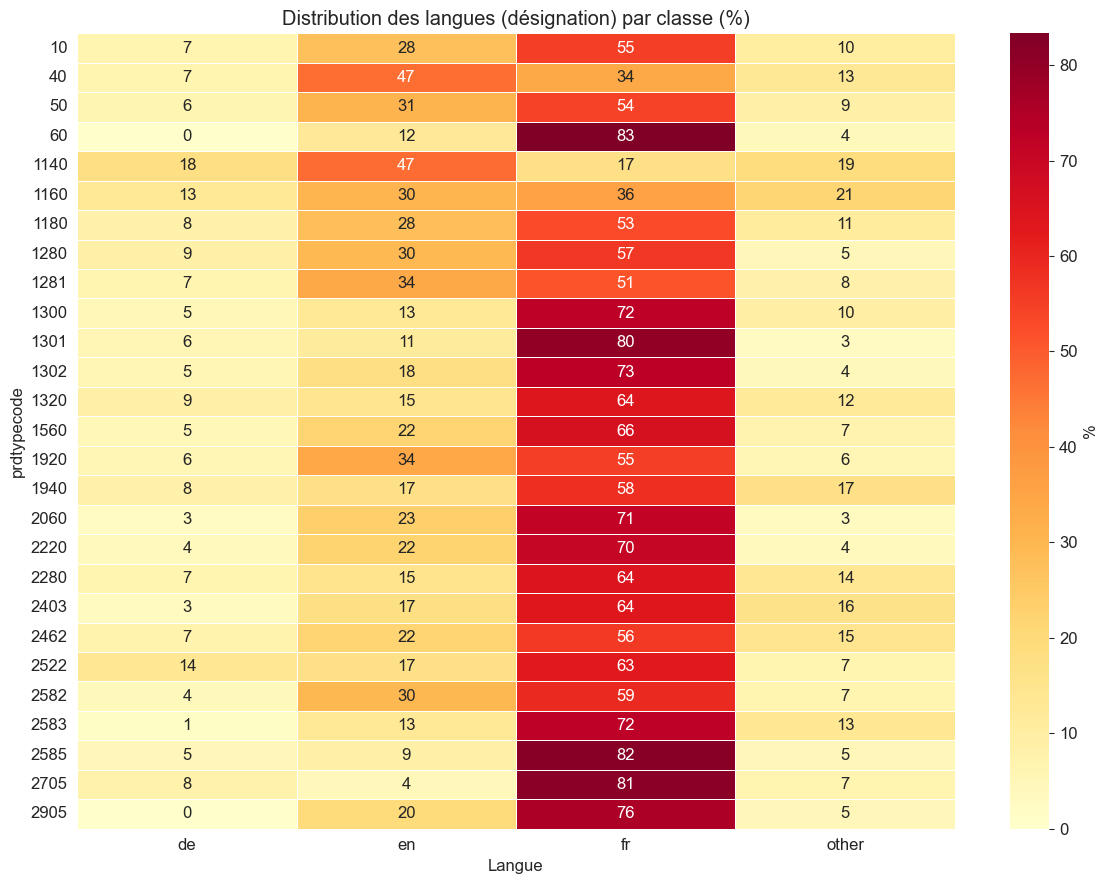

In [44]:
# Heatmap : langue de la désignation par classe
lang_class = sample_ld.groupby(['prdtypecode', 'lang_desig_grp']).size().unstack(fill_value=0)
# Normaliser par ligne (% par classe)
lang_class_pct = lang_class.div(lang_class.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(lang_class_pct, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, cbar_kws={'label': '%'})
ax.set_title("Distribution des langues (désignation) par classe (%)")
ax.set_xlabel("Langue")
ax.set_ylabel("prdtypecode")
plt.tight_layout()
plt.show()

In [45]:
# ── Conclusion : faut-il traduire ? ─────────────────────────────────────────
pct_fr  = (sample_ld['lang_designation'] == 'fr').mean() * 100
pct_non_fr = 100 - pct_fr - (sample_ld['lang_designation'] == 'unknown').mean() * 100

print("=" * 60)
print("ANALYSE : Faut-il traduire les textes ?")
print("=" * 60)
print(f"  Français        : {pct_fr:.1f}%")
print(f"  Autres langues  : {pct_non_fr:.1f}%")
print()
print("APPROCHES POSSIBLES :")
print()
print("  ① Ne PAS traduire — utiliser un modèle multilingue")
print("     → XLM-RoBERTa, mBERT : gèrent nativement 100+ langues")
print("     → TF-IDF / Bag-of-Words : insensible à la langue")
print("       (les tokens sont différents mais le modèle apprend)")
print("     ✅ Avantage : aucun coût de traduction, rapide")
print("     ✅ TF-IDF fonctionne bien même multilingue (benchmark=0.81)")
print()
print("  ② Traduire tout en français")
print("     → Utiliser deep-translator ou googletrans")
print("     → Puis CamemBERT (French BERT) pour de meilleures perfs")
print("     ⚠️  Coût : ~99k requêtes API, temps de traitement élevé")
print()
print("RECOMMANDATION pour ce projet :")
print("  → Commencer SANS traduction avec TF-IDF + LogReg ou XGBoost")
print("  → La majorité du texte est FR/multilingue cohérent par classe")
print("  → La langue est souvent un signal de classe (ex: livres DE, EN)")
print("  → Traduire uniquement si les perfs sont insuffisantes")

ANALYSE : Faut-il traduire les textes ?
  Français        : 62.2%
  Autres langues  : 37.8%

APPROCHES POSSIBLES :

  ① Ne PAS traduire — utiliser un modèle multilingue
     → XLM-RoBERTa, mBERT : gèrent nativement 100+ langues
     → TF-IDF / Bag-of-Words : insensible à la langue
       (les tokens sont différents mais le modèle apprend)
     ✅ Avantage : aucun coût de traduction, rapide
     ✅ TF-IDF fonctionne bien même multilingue (benchmark=0.81)

  ② Traduire tout en français
     → Utiliser deep-translator ou googletrans
     → Puis CamemBERT (French BERT) pour de meilleures perfs
     ⚠️  Coût : ~99k requêtes API, temps de traitement élevé

RECOMMANDATION pour ce projet :
  → Commencer SANS traduction avec TF-IDF + LogReg ou XGBoost
  → La majorité du texte est FR/multilingue cohérent par classe
  → La langue est souvent un signal de classe (ex: livres DE, EN)
  → Traduire uniquement si les perfs sont insuffisantes


---
## 5. Analyse des Images
### 5.1 Vérification de la disponibilité des images

In [46]:
def get_img_path(row, folder):
    return os.path.join(folder, f"image_{row['imageid']}_product_{row['productid']}.jpg")

# Vérif sur un échantillon de 500
sample_check = train.sample(500, random_state=42)
sample_check['img_exists'] = sample_check.apply(
    lambda r: os.path.exists(get_img_path(r, IMG_TRAIN_PATH)), axis=1
)

pct_found = sample_check['img_exists'].mean()
print(f"Images trouvées dans le dossier (échantillon 500) : {pct_found:.1%}")

if pct_found == 0:
    print(f"\nATTENTION : Aucune image trouvée dans {IMG_TRAIN_PATH}")
    print("Vérifiez que le dossier 'images/image_train' est bien présent dans le répertoire Rakuten.")

Images trouvées dans le dossier (échantillon 500) : 100.0%


### 5.2 Visualisation d'exemples d'images par classe

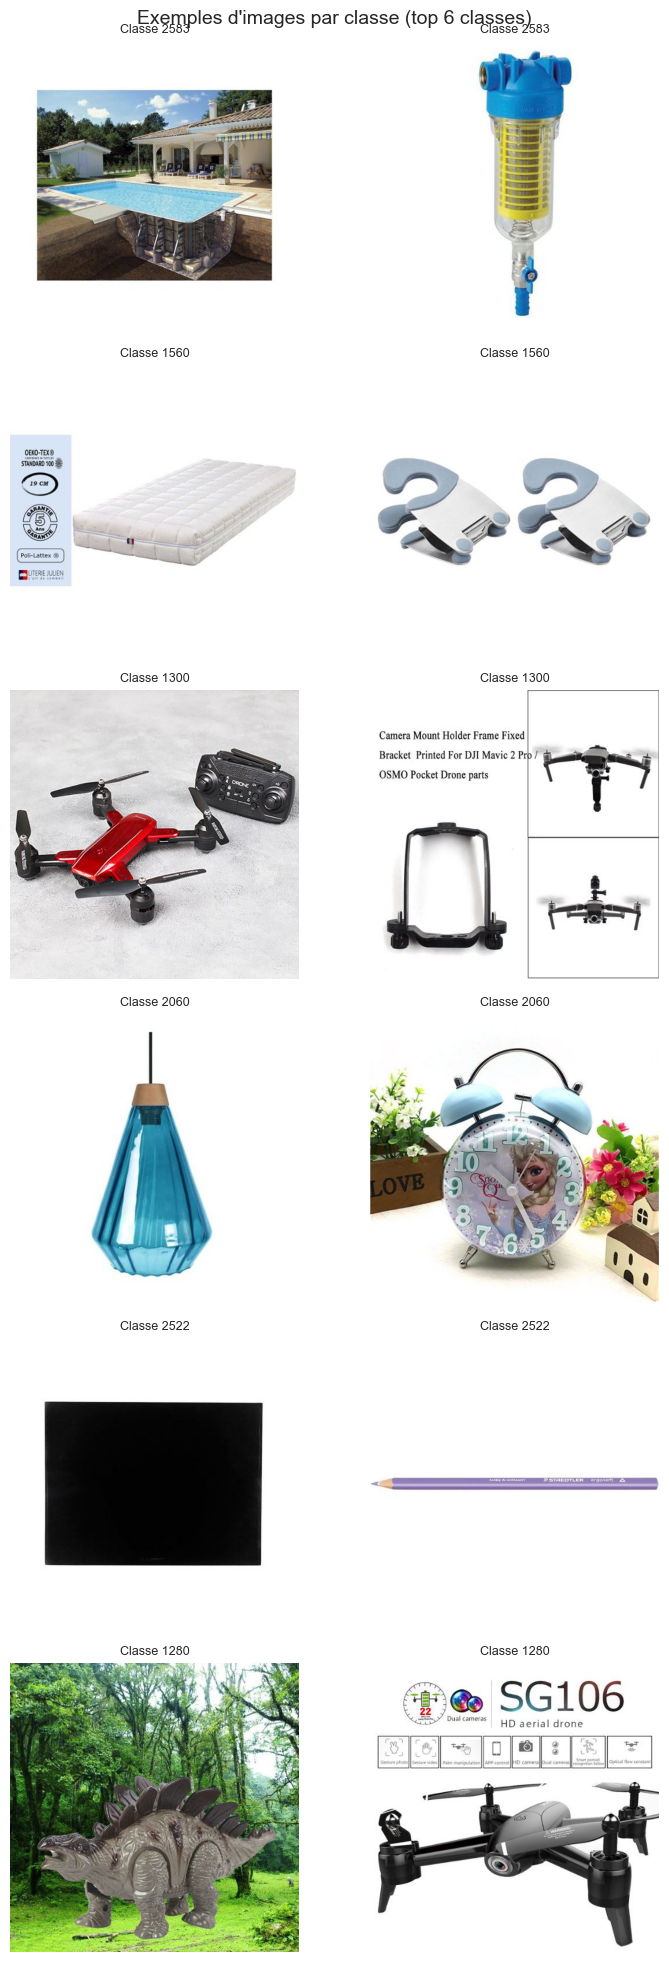

In [47]:
# Affiche 2 exemples pour 6 classes aléatoires
selected_classes = train['prdtypecode'].value_counts().head(6).index.tolist()

fig, axes = plt.subplots(6, 2, figsize=(8, 20))
fig.suptitle("Exemples d'images par classe (top 6 classes)", fontsize=14)

for i, cls in enumerate(selected_classes):
    subset = train[train['prdtypecode'] == cls]
    examples = subset.sample(min(2, len(subset)), random_state=42)
    for j, (_, row) in enumerate(examples.iterrows()):
        img_path = get_img_path(row, IMG_TRAIN_PATH)
        ax = axes[i][j]
        if os.path.exists(img_path):
            img = mpimg.imread(img_path)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, 'Image non\ntrouvée', ha='center', va='center', transform=ax.transAxes)
            ax.set_facecolor('#f0f0f0')
        ax.set_title(f"Classe {cls}", fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.show()

### 5.3 Taille des images (échantillon)

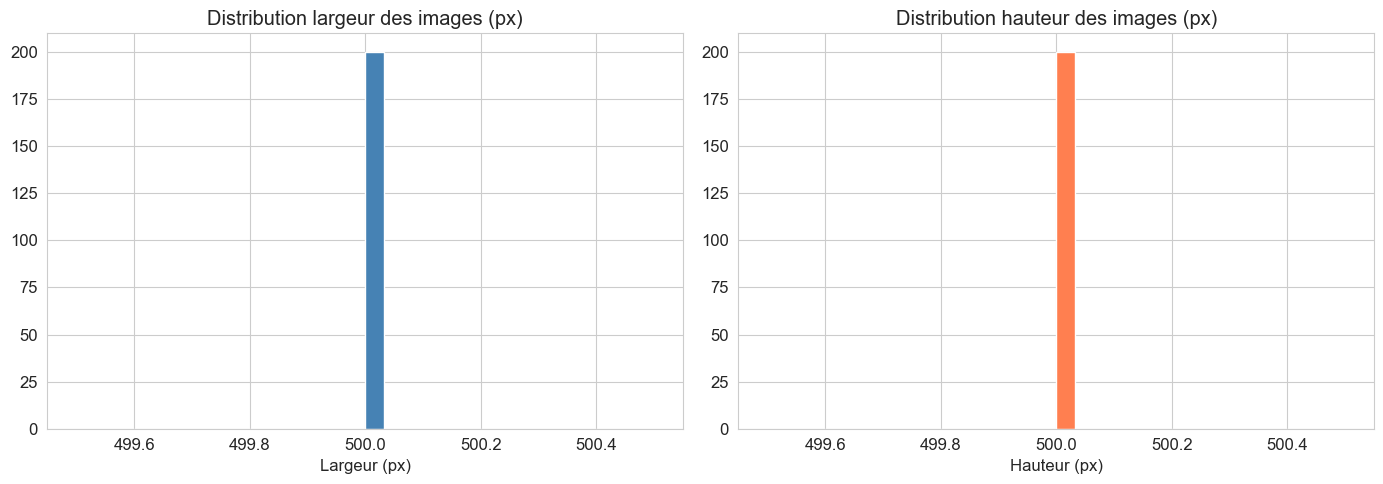

Largeur  : médiane=500px, min=500px, max=500px
Hauteur  : médiane=500px, min=500px, max=500px


In [48]:
from PIL import Image

widths, heights = [], []
sample_img = train.sample(200, random_state=42)

for _, row in sample_img.iterrows():
    img_path = get_img_path(row, IMG_TRAIN_PATH)
    if os.path.exists(img_path):
        try:
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
        except:
            pass

if widths:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(widths, bins=30, color='steelblue', edgecolor='white')
    axes[0].set_title("Distribution largeur des images (px)")
    axes[0].set_xlabel("Largeur (px)")
    axes[1].hist(heights, bins=30, color='coral', edgecolor='white')
    axes[1].set_title("Distribution hauteur des images (px)")
    axes[1].set_xlabel("Hauteur (px)")
    plt.tight_layout()
    plt.show()
    print(f"Largeur  : médiane={np.median(widths):.0f}px, min={min(widths)}px, max={max(widths)}px")
    print(f"Hauteur  : médiane={np.median(heights):.0f}px, min={min(heights)}px, max={max(heights)}px")
else:
    print("Aucune image trouvée pour l'analyse de taille.")

### 5.4 Détection des images à fond blanc dominant (>70%) et auto-recadrage

Images trouvées dans l'échantillon : 1000
Calcul du ratio de pixels blancs...

Images avec >70% de pixels blancs : 313 / 1000 (31.3%)


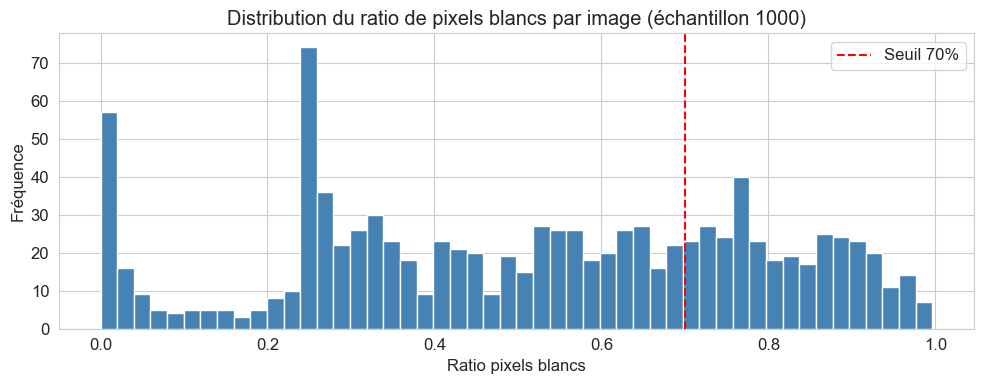

In [49]:
from PIL import Image
import numpy as np

WHITE_THRESHOLD = 240   # pixel >= cette valeur sur R,G,B = "blanc"
WHITE_RATIO_MIN = 0.70  # seuil : image considérée à fond blanc

def white_ratio(img_path):
    """Retourne la proportion de pixels blancs (R,G,B >= WHITE_THRESHOLD)."""
    try:
        with Image.open(img_path) as img:
            arr = np.array(img.convert('RGB'))
            mask = np.all(arr >= WHITE_THRESHOLD, axis=2)
            return mask.mean()
    except Exception:
        return None

# Analyse sur un échantillon de 1000 images
sample_white = train.sample(1000, random_state=42).copy()
sample_white['img_path']    = sample_white.apply(lambda r: get_img_path(r, IMG_TRAIN_PATH), axis=1)
sample_white['img_exists']  = sample_white['img_path'].apply(os.path.exists)
sample_white = sample_white[sample_white['img_exists']]

print(f"Images trouvées dans l'échantillon : {len(sample_white)}")
print("Calcul du ratio de pixels blancs...")

sample_white['white_ratio'] = sample_white['img_path'].apply(white_ratio)
sample_white = sample_white.dropna(subset=['white_ratio'])

n_white = (sample_white['white_ratio'] >= WHITE_RATIO_MIN).sum()
pct_white = n_white / len(sample_white) * 100

print(f"\nImages avec >70% de pixels blancs : {n_white} / {len(sample_white)} ({pct_white:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sample_white['white_ratio'], bins=50, color='steelblue', edgecolor='white')
ax.axvline(WHITE_RATIO_MIN, color='red', linestyle='--', label=f'Seuil {WHITE_RATIO_MIN:.0%}')
ax.set_title("Distribution du ratio de pixels blancs par image (échantillon 1000)")
ax.set_xlabel("Ratio pixels blancs")
ax.set_ylabel("Fréquence")
ax.legend()
plt.tight_layout()
plt.show()

Affichage de 10 images à fond blanc (>70%)


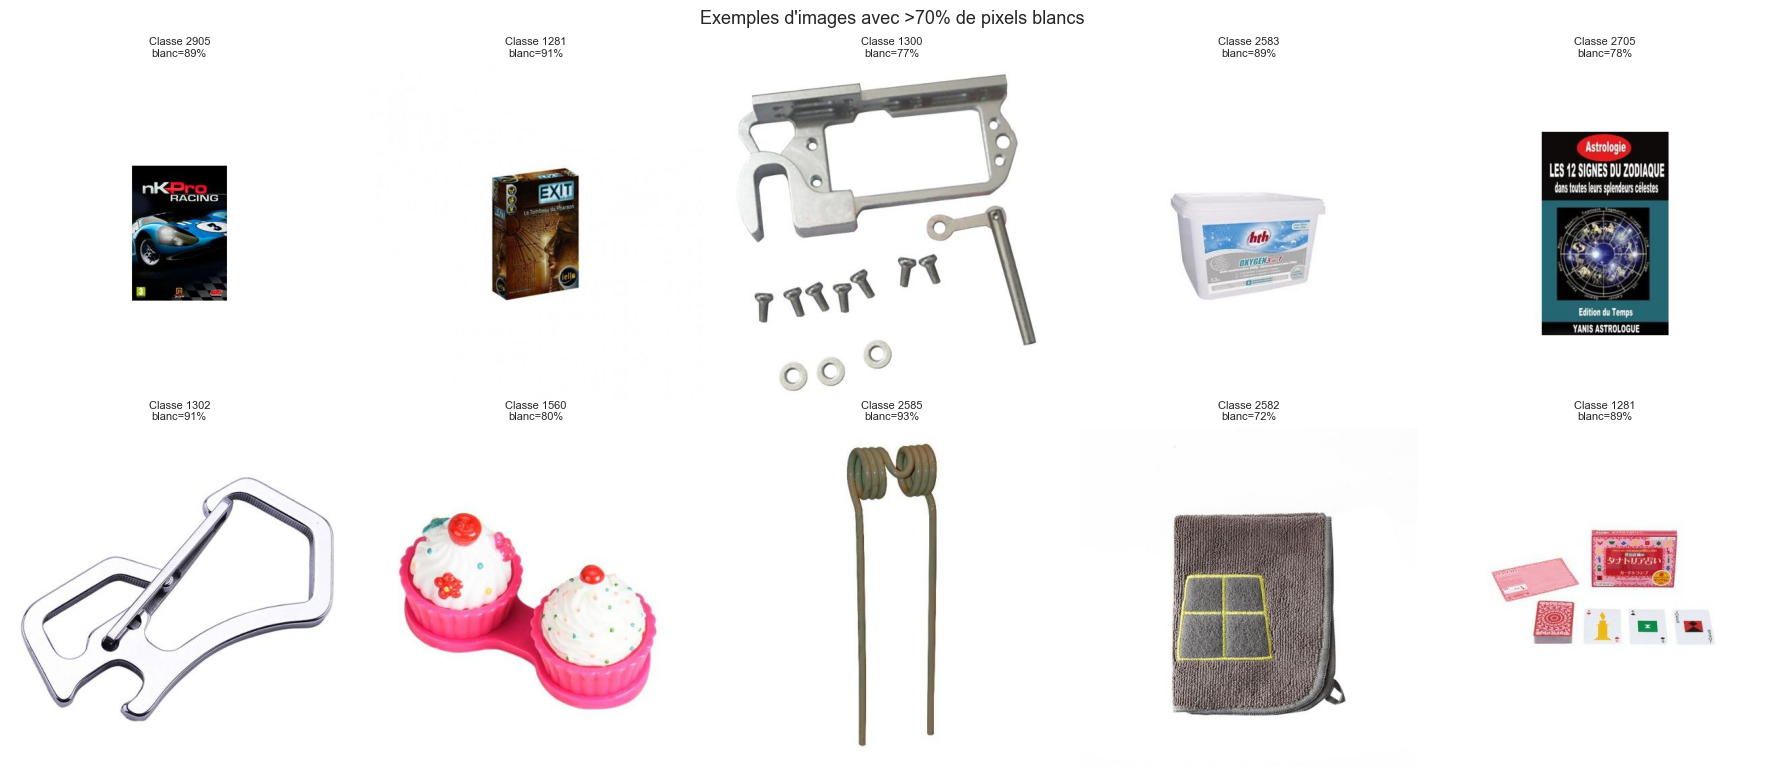

In [50]:
# Afficher 10 exemples d'images à fond blanc dominant
white_imgs = sample_white[sample_white['white_ratio'] >= WHITE_RATIO_MIN].head(10)
print(f"Affichage de {len(white_imgs)} images à fond blanc (>70%)")

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
fig.suptitle("Exemples d'images avec >70% de pixels blancs", fontsize=13)

for ax, (_, row) in zip(axes.flatten(), white_imgs.iterrows()):
    img = Image.open(row['img_path']).convert('RGB')
    ax.imshow(img)
    ax.set_title(f"Classe {row['prdtypecode']}\nblanc={row['white_ratio']:.0%}", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

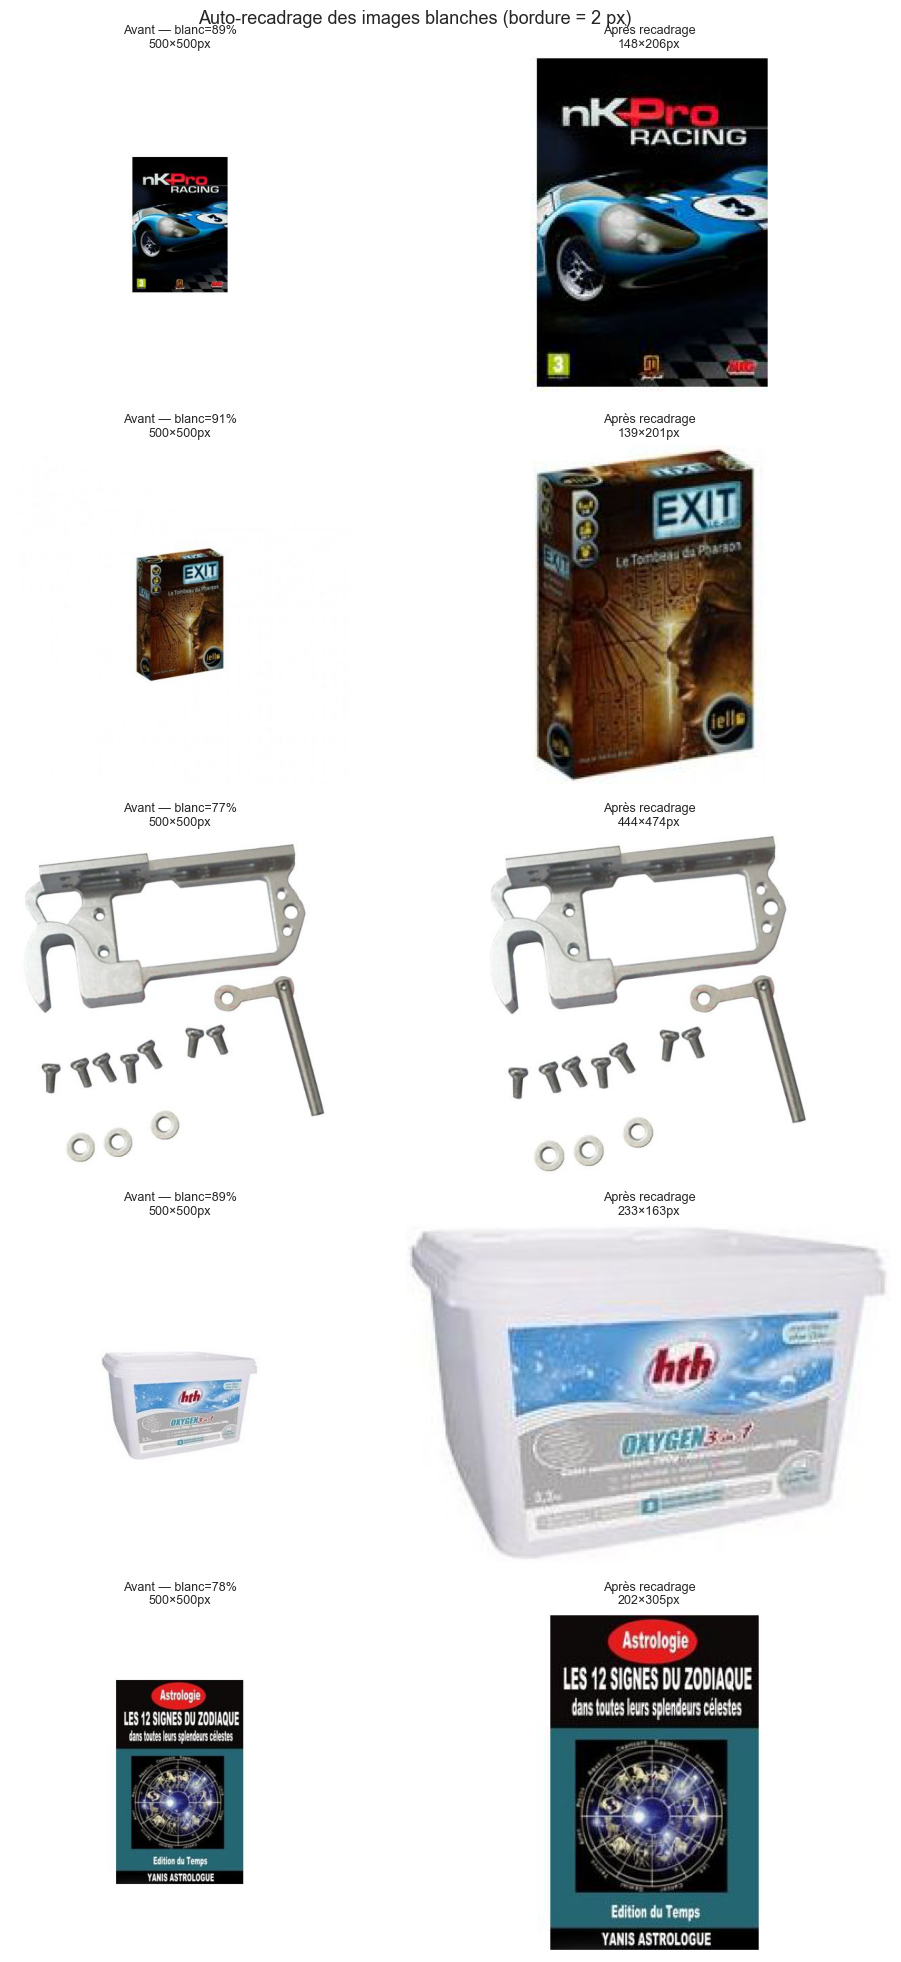

In [51]:
def autocrop_white(img_path, border=2, white_thresh=WHITE_THRESHOLD):
    """
    Recadre automatiquement une image en supprimant le fond blanc.
    Conserve `border` pixels de marge autour du contenu.
    
    Retourne (img_originale, img_recadree) en tant que PIL Images.
    """
    img_orig = Image.open(img_path).convert('RGB')
    arr = np.array(img_orig)
    
    # Masque des pixels NON blancs
    non_white = ~np.all(arr >= white_thresh, axis=2)
    
    if not non_white.any():
        # Image entièrement blanche : on retourne l'originale
        return img_orig, img_orig
    
    # Bounding box du contenu non-blanc
    rows = np.any(non_white, axis=1)
    cols = np.any(non_white, axis=0)
    
    r_min, r_max = np.where(rows)[0][[0, -1]]
    c_min, c_max = np.where(cols)[0][[0, -1]]
    
    # Ajouter la bordure de `border` pixels (clamp aux dimensions de l'image)
    h, w = arr.shape[:2]
    r_min = max(0, r_min - border)
    r_max = min(h - 1, r_max + border)
    c_min = max(0, c_min - border)
    c_max = min(w - 1, c_max + border)
    
    img_crop = img_orig.crop((c_min, r_min, c_max + 1, r_max + 1))
    return img_orig, img_crop


# Afficher avant / après pour les 5 premières images blanches
n_show = 5
white_sample = white_imgs.head(n_show)

fig, axes = plt.subplots(n_show, 2, figsize=(10, n_show * 4))
fig.suptitle(f"Auto-recadrage des images blanches (bordure = 2 px)", fontsize=13)

for i, (_, row) in enumerate(white_sample.iterrows()):
    orig, cropped = autocrop_white(row['img_path'], border=2)
    
    axes[i][0].imshow(orig)
    axes[i][0].set_title(f"Avant — blanc={row['white_ratio']:.0%}\n{orig.size[0]}×{orig.size[1]}px", fontsize=9)
    axes[i][0].axis('off')
    
    axes[i][1].imshow(cropped)
    axes[i][1].set_title(f"Après recadrage\n{cropped.size[0]}×{cropped.size[1]}px", fontsize=9)
    axes[i][1].axis('off')

plt.tight_layout()
plt.show()

In [52]:
# Ratio de réduction de surface après recadrage
reductions = []
for _, row in white_imgs.iterrows():
    orig, cropped = autocrop_white(row['img_path'], border=2)
    orig_area    = orig.size[0] * orig.size[1]
    cropped_area = cropped.size[0] * cropped.size[1]
    reductions.append(1 - cropped_area / orig_area)

reductions = np.array(reductions)
print(f"Réduction de surface après recadrage (sur {len(reductions)} images blanches) :")
print(f"  Médiane : {np.median(reductions):.1%}")
print(f"  Min     : {reductions.min():.1%}")
print(f"  Max     : {reductions.max():.1%}")
print()
print("CONCLUSION :")
print(f"  Le recadrage supprime en médiane {np.median(reductions):.0%} de la surface inutile.")
print("  Pour la modélisation, appliquer autocrop_white() AVANT le resize 224×224")
print("  → le sujet occupe alors une plus grande portion de l'image → meilleure classification.")

Réduction de surface après recadrage (sur 10 images blanches) :
  Médiane : 75.1%
  Min     : 15.8%
  Max     : 88.8%

CONCLUSION :
  Le recadrage supprime en médiane 75% de la surface inutile.
  Pour la modélisation, appliquer autocrop_white() AVANT le resize 224×224
  → le sujet occupe alors une plus grande portion de l'image → meilleure classification.


---
## 6. Pre-processing
### 6.1 Nettoyage du texte

In [53]:
class MLStripper(HTMLParser):
    """Supprime les balises HTML."""
    def __init__(self):
        super().__init__()
        self.reset()
        self.fed = []
    def handle_data(self, d):
        self.fed.append(d)
    def get_data(self):
        return ' '.join(self.fed)

def strip_html(text):
    s = MLStripper()
    s.feed(str(text))
    return s.get_data()

def clean_text(text):
    """Nettoyage complet d'un texte."""
    if not isinstance(text, str):
        return ''
    # Supprimer HTML
    text = strip_html(text)
    # Décoder les entités HTML résiduelles
    text = text.replace('&amp;', '&').replace('&lt;', '<').replace('&gt;', '>').replace('&nbsp;', ' ')
    # Normaliser unicode
    text = unicodedata.normalize('NFC', text)
    # Minuscules
    text = text.lower()
    # Supprimer caractères spéciaux, garder lettres, chiffres, espaces
    text = re.sub(r'[^\w\s]', ' ', text)
    # Supprimer les chiffres seuls (optionnel)
    # text = re.sub(r'\b\d+\b', '', text)
    # Espaces multiples
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Test
sample_text = train['description'].dropna().iloc[2]
print("AVANT :", sample_text[:200])
print("\nAPRÈS :", clean_text(sample_text)[:200])

AVANT : CONQUERANT CLASSIQUE Cahier 240 x 320 mm seyès incolorecouverture en Polypro 96 pages agrafé papier de 90 g/m2(400006764)

APRÈS : conquerant classique cahier 240 x 320 mm seyès incolorecouverture en polypro 96 pages agrafé papier de 90 g m2 400006764


In [54]:
# Application sur tout le dataset
print("Nettoyage des textes en cours...")

train['designation_clean'] = train['designation'].apply(clean_text)
X_test['designation_clean'] = X_test['designation'].apply(clean_text)

train['description_clean'] = train['description'].apply(
    lambda x: clean_text(x) if isinstance(x, str) else ''
)
X_test['description_clean'] = X_test['description'].apply(
    lambda x: clean_text(x) if isinstance(x, str) else ''
)

# Combinaison texte : désignation + description
train['text_combined'] = (train['designation_clean'] + ' ' + train['description_clean']).str.strip()
X_test['text_combined'] = (X_test['designation_clean'] + ' ' + X_test['description_clean']).str.strip()

print("Nettoyage terminé.")
print(f"\nExemple text_combined :\n{train['text_combined'].iloc[2][:300]}")

Nettoyage des textes en cours...
Nettoyage terminé.

Exemple text_combined :
grand stylet ergonomique bleu gamepad nintendo wii u speedlink pilot style pilot style touch pen de marque speedlink est 1 stylet ergonomique pour gamepad nintendo wii u pour un confort optimal et une précision maximale sur le gamepad de la wii u ce grand stylet hautement ergonomique est non seuleme


### 6.2 Statistiques post-nettoyage

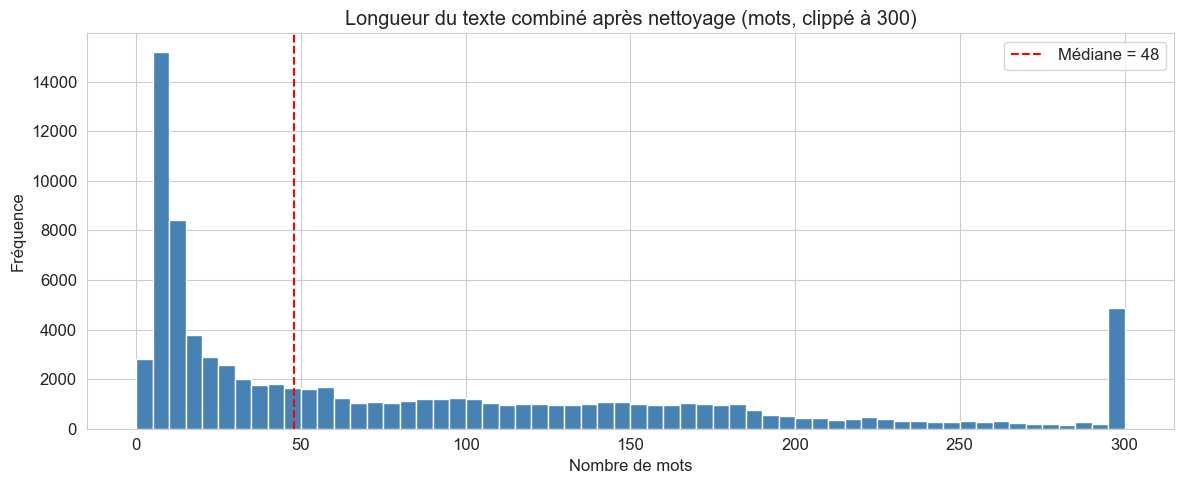

count    84916.000000
mean        92.951258
std        118.492038
min          0.000000
25%         11.000000
50%         48.000000
75%        141.000000
max       2141.000000
Name: text_combined_len, dtype: float64


In [55]:
train['text_combined_len'] = train['text_combined'].apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(12, 5))
train['text_combined_len'].clip(upper=300).hist(bins=60, ax=ax, color='steelblue', edgecolor='white')
ax.set_title("Longueur du texte combiné après nettoyage (mots, clippé à 300)")
ax.set_xlabel("Nombre de mots")
ax.set_ylabel("Fréquence")
ax.axvline(train['text_combined_len'].median(), color='red', linestyle='--', 
           label=f"Médiane = {train['text_combined_len'].median():.0f}")
ax.legend()
plt.tight_layout()
plt.show()

print(train['text_combined_len'].describe())

### 6.3 Encodage de la variable cible

In [56]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
train['label'] = le.fit_transform(train['prdtypecode'])

print(f"Classes originales : {le.classes_}")
print(f"\nNombre de classes : {len(le.classes_)}")
print(f"\nMapping (5 premiers) :")
for i, c in enumerate(le.classes_[:5]):
    print(f"  {c} -> {i}")

Classes originales : [  10   40   50   60 1140 1160 1180 1280 1281 1300 1301 1302 1320 1560
 1920 1940 2060 2220 2280 2403 2462 2522 2582 2583 2585 2705 2905]

Nombre de classes : 27

Mapping (5 premiers) :
  10 -> 0
  40 -> 1
  50 -> 2
  60 -> 3
  1140 -> 4


### 6.4 Vérification du déséquilibre des classes

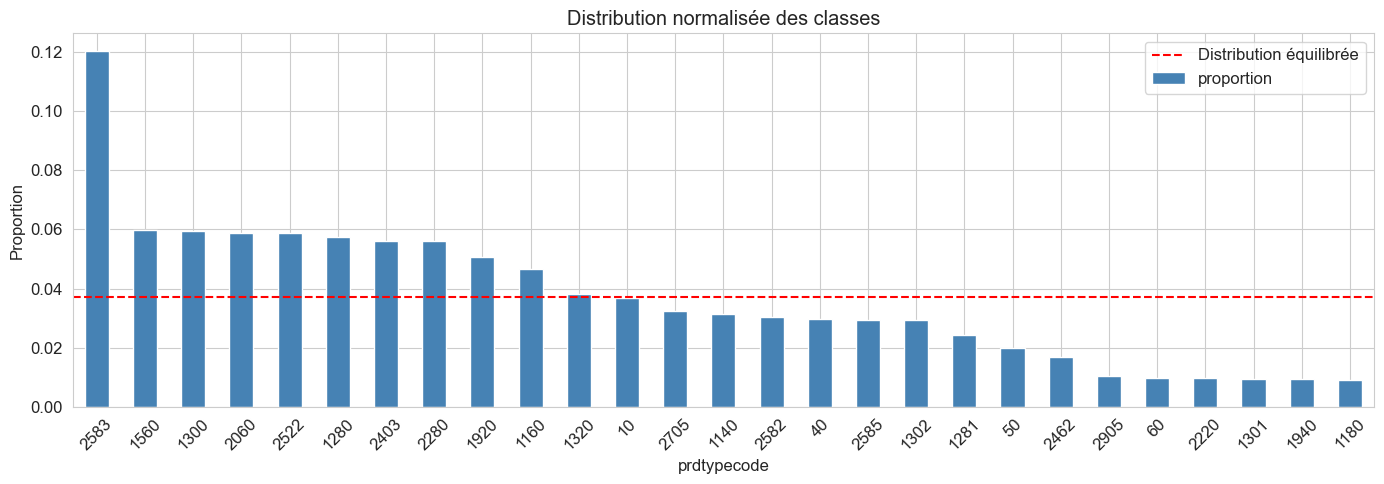

Classe la plus fréquente  : 2583 = 12.02%
Classe la moins fréquente : 1180 = 0.90%
Distribution équilibrée   : 3.70%


In [57]:
class_dist = train['prdtypecode'].value_counts(normalize=True).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 5))
class_dist.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title("Distribution normalisée des classes")
ax.set_xlabel("prdtypecode")
ax.set_ylabel("Proportion")
ax.axhline(1/len(class_dist), color='red', linestyle='--', label='Distribution équilibrée')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Classe la plus fréquente  : {class_dist.index[0]} = {class_dist.iloc[0]:.2%}")
print(f"Classe la moins fréquente : {class_dist.index[-1]} = {class_dist.iloc[-1]:.2%}")
print(f"Distribution équilibrée   : {1/len(class_dist):.2%}")

### 6.5 Split train/validation

In [58]:
from sklearn.model_selection import train_test_split

X = train[['text_combined', 'designation_clean', 'description_clean', 'productid', 'imageid']]
y = train['label']

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train     : {X_tr.shape[0]} lignes")
print(f"Validation: {X_val.shape[0]} lignes")
print(f"\nDistribution classes (train vs val) :")
print(pd.DataFrame({'train': y_tr.value_counts(normalize=True).sort_index(),
                    'val'  : y_val.value_counts(normalize=True).sort_index()}).head(10))

Train     : 67932 lignes
Validation: 16984 lignes

Distribution classes (train vs val) :
          train       val
label                    
0      0.036698  0.036682
1      0.029530  0.029557
2      0.019799  0.019783
3      0.009804  0.009774
4      0.031458  0.031441
5      0.046547  0.046573
6      0.008994  0.009008
7      0.057351  0.057348
8      0.024377  0.024376
9      0.059412  0.059409


---
## 7. Sauvegarde des données pré-traitées

In [61]:
os.makedirs(PROCESSED_PATH, exist_ok=True)

# Sauvegarder
train[['designation_clean', 'description_clean', 'text_combined', 'productid', 'imageid', 'prdtypecode', 'label']].to_csv(
    os.path.join(PROCESSED_PATH, 'train_processed.csv')
)
X_test[['designation_clean', 'description_clean', 'text_combined', 'productid', 'imageid']].to_csv(
    os.path.join(PROCESSED_PATH, 'test_processed.csv')
)

# Sauvegarder le LabelEncoder
import pickle
with open(os.path.join(PROCESSED_PATH, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(le, f)

print(f"Données sauvegardées dans : {PROCESSED_PATH}")
print(f"  - train_processed.csv")
print(f"  - test_processed.csv")
print(f"  - label_encoder.pkl")

Données sauvegardées dans : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed_final
  - train_processed.csv
  - test_processed.csv
  - label_encoder.pkl


---
## 8. Résumé de l'Exploration

| Aspect | Résultat |
|--------|----------|
| **Taille train** | 84 916 produits |
| **Taille test** | 13 812 produits |
| **Nombre de classes** | 27 prdtypecodes |
| **Valeurs manquantes** | `description` ~47% manquante |
| **Déséquilibre classes** | Ratio max/min élevé → utiliser weighted F1 |
| **Langue dominante** | Français (mais présence d'anglais et autres) |
| **Longueur désignation** | Médiane ~8 mots, max ~34 mots |
| **Longueur description** | Très variable (0 à 1000+ mots) |

### Points clés pour la modélisation :
1. **Texte** : Combiner désignation + description nettoyées → TF-IDF ou embeddings
2. **Valeurs manquantes** : Description absente remplacée par `''` → stratégie d'imputation possible
3. **Déséquilibre** : Penser à `class_weight='balanced'` dans les modèles
4. **Images** : Prétraitement standardisé (resize 224×224 pour ResNet)
5. **Métrique** : Toujours évaluer avec `f1_score(..., average='weighted')`